# 04 - A/B experiment

Design (power), simulated targeted-coupon test, SRM, CUPED, Bayesian analysis and the peeking pitfall (`src/ecom/experiment`).

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from ecom.config import get_config
from ecom.layout import outputs_dir, table_path
cfg = get_config()
OUT = outputs_dir(cfg)
FIG = cfg.paths.figures
pd.set_option("display.float_format", "{:,.4f}".format)
print(f"source={cfg.source} sample={cfg.sample_rate:.0%} outputs={OUT}")

source=synthetic sample=100% outputs=D:\smaiproj\data\outputs\synthetic\full


## How many users do we need? (power curve)

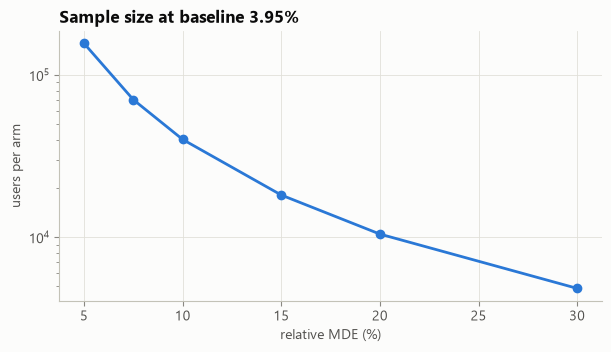

In [2]:
import matplotlib.pyplot as plt
import ecom.viz  # house style
from ecom.stats.power import sample_size_two_proportions
ab = json.loads((OUT / 'ab_results.json').read_text())
base = ab['design']['baseline_rate']
mdes = [0.05, 0.075, 0.1, 0.15, 0.2, 0.3]
n = [sample_size_two_proportions(base, m).n_per_arm for m in mdes]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([m * 100 for m in mdes], n, marker='o')
ax.set(xlabel='relative MDE (%)', ylabel='users per arm', yscale='log', title=f'Sample size at baseline {base:.2%}')
plt.show()

In [3]:
pd.Series(ab['design'])

baseline_rate                                                      0.0395
mde_relative                                                       0.1000
target_rate                                                        0.0434
alpha                                                              0.0500
power                                                              0.8000
effect_size_h                                                      0.0198
n_per_arm                                                           40022
n_total                                                             80044
daily_eligible_users                                          26,290.4098
duration_days                                                           4
population                                                         209548
n_per_arm_available                                                104774
mde_at_available_n                                                 0.0613
power_at_available_n                  

## Results

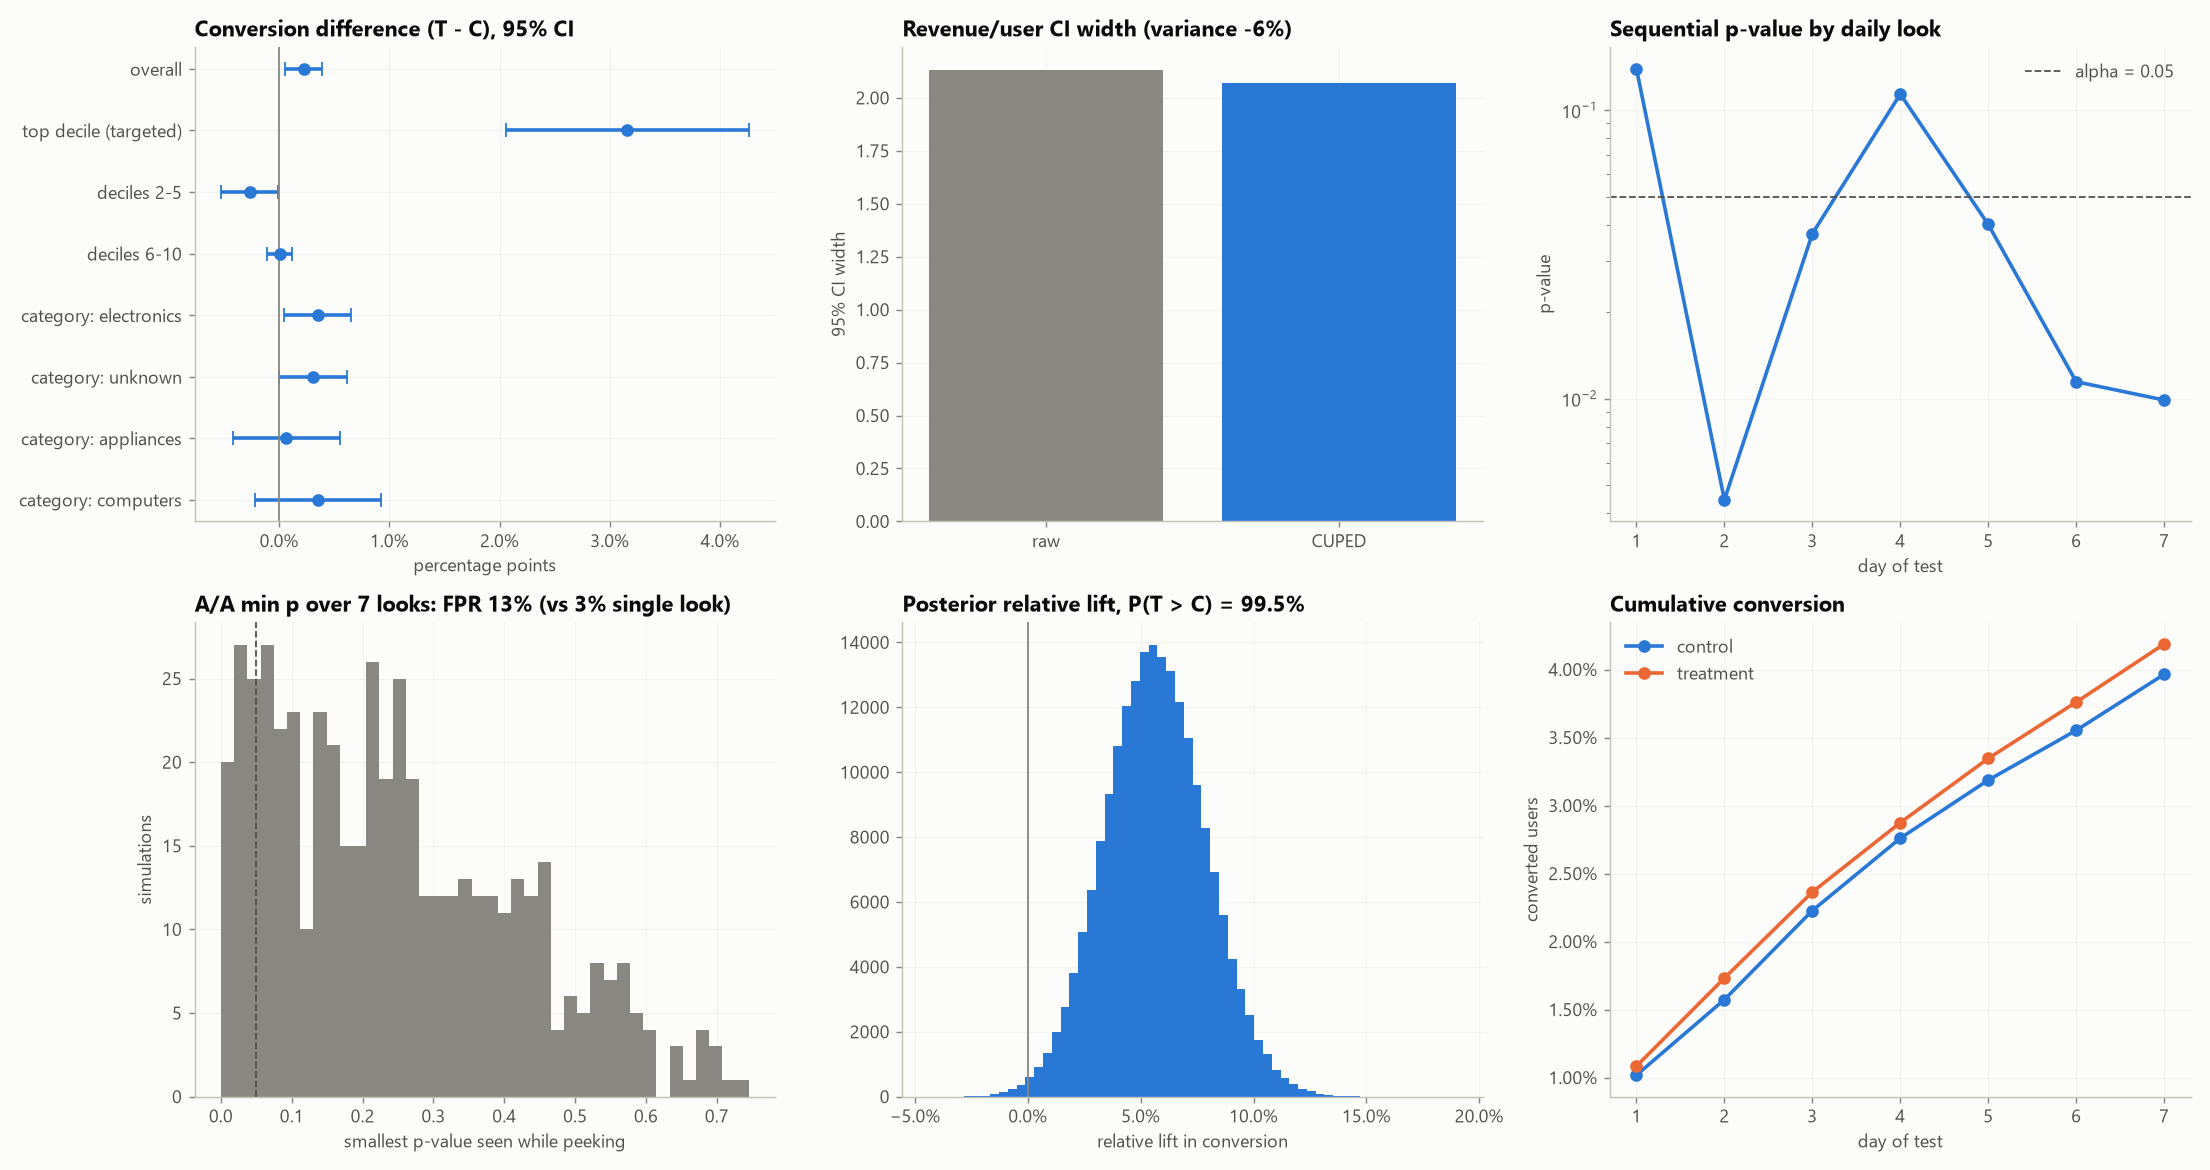

,group,users,converted,conversion,revenue,revenue_per_user,treated,simulated_conversions
0,control,104682,4150,0.0396,"1,468,296.5400",14.0263,0,0
1,treatment,104866,4391,0.0419,"1,422,044.0118",13.5606,10551,273


,segment,n_control,n_treatment,conv_control,conv_treatment,diff,ci_low,ci_high,relative_lift,p_value,p_bh
0,top decile (targeted),10403,10551,0.1935,0.2251,0.0316,0.0206,0.0426,0.1633,0.0000,0.0000
1,deciles 2-5,42119,41701,0.0398,0.0371,-0.0027,-0.0053,-0.0001,-0.0671,0.0445,0.0866
2,deciles 6-10,52160,52614,0.0088,0.0089,0.0001,-0.0011,0.0012,0.0065,0.9216,0.9216
3,category: electronics,37444,37261,0.0447,0.0482,0.0035,0.0005,0.0065,0.0781,0.0233,0.0815
4,category: unknown,28665,28778,0.0354,0.0385,0.0031,0.0000,0.0062,0.0873,0.0495,0.0866
5,category: appliances,12572,12643,0.0399,0.0405,0.0006,-0.0042,0.0055,0.0162,0.7939,0.9216
6,category: computers,8380,8426,0.0354,0.0389,0.0035,-0.0022,0.0092,0.0983,0.2325,0.3255


In [4]:
display(Image(FIG / "experiment_summary.png"))
display(pd.read_csv(OUT / "ab_arms.csv"))
display(pd.read_csv(OUT / "ab_segments.csv"))

In [5]:
print('SRM p =', round(ab['srm']['p_value'], 4))
print('CUPED variance reduction:', f"{ab['revenue']['cuped_stats']['variance_reduction']:.1%}")
print('P(treatment better):', f"{ab['bayesian']['prob_treatment_better']:.1%}")
print('Peeking FPR:', f"{ab['peeking']['fpr_any_look']:.1%}", 'vs', f"{ab['peeking']['fpr_final_look_only']:.1%}")

SRM p = 0.6877
CUPED variance reduction: 5.7%
P(treatment better): 99.5%
Peeking FPR: 13.0% vs 3.2%


## Decision

In [6]:
display(Markdown(f"**{ab['decision']['verdict']}**\n\n" + '\n'.join('- ' + r for r in ab['decision']['reasons'])))

**SHIP**

- SRM check passed (p = 0.688).
- Conversion 3.96% -> 4.19% (+5.6% relative, p = 0.00989): significant improvement.
- Revenue/user (CUPED) diff -0.50 [-1.54, +0.53]: no significant harm.
- Buyer AOV -1.9% (p = 0.411); guardrail allows at most -10%: within guardrail.